LN Project - Baseline

Environment Setup & Imports

In [1]:
import pandas as pd
import numpy as np
import re
import random
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Set reproducibility seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Executing on device: {device}")

Executing on device: cuda


Data Loading & Cleaning

In [2]:
# 1. Load dataset safely
df = pd.read_csv('train.csv', sep=';', on_bad_lines='skip', quotechar='"')

# 2. Strip whitespace
df.columns = df.columns.str.strip()
df['medical_specialty'] = df['medical_specialty'].str.strip()

# 3. Filter valid specialties (support > 10)
valid_specialties = df['medical_specialty'].value_counts()
valid_specialties = valid_specialties[valid_specialties > 10].index.tolist()
df = df[df['medical_specialty'].isin(valid_specialties)].copy().reset_index(drop=True)

# 4. Fill missing values with empty strings
df['sample_name'] = df['sample_name'].fillna("")
df['description'] = df['description'].fillna("")
df['keywords'] = df['keywords'].fillna("")
df['transcription'] = df['transcription'].fillna("")

print(f"Total valid samples loaded: {len(df)}")
print(f"Classes ({len(valid_specialties)}): {sorted(valid_specialties)}")

Total valid samples loaded: 2613
Classes (12): ['Cardiovascular-Pulmonary', 'Dermatology', 'Gastroenterology', 'General Medicine', 'Neurology', 'Neurosurgery', 'Obstetrics-Gynecology', 'Ophthalmology', 'Orthopedic', 'Psychiatry-Psychology', 'Radiology', 'Surgery']


Text Pre-processing and Weighted Concatenation

In [3]:
# 5. Feature Engineering: Weighted Concatenation
df['weighted_text'] = (
    df['sample_name'] + " " + df['sample_name'] + " " +
    df['description'] + " " +
    df['keywords'] + " " + df['keywords'] + " " +
    df['transcription']
)

# 6. Medical Text Normalization (preserving clinical words and negations)
def clean_medical_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'[^\w\s]', ' ', text)
    return " ".join(text.split())

df['clean_weighted_text'] = df['weighted_text'].apply(clean_medical_text)

print(f"Total samples processed: {len(df)}")
print("\nSample preview:")
print(df['clean_weighted_text'].iloc[0][:300] + "...")

Total samples processed: 2613

Sample preview:
chest pain cardiac consult chest pain cardiac consult chest pain possible syncopal spells she has been having multiple cardiovascular complaints including chest pains which feel like cramps and sometimes like a dull ache which will last all day long cardiovascular pulmonary chest pain syncopal echoc...


Train / Validation Split

In [4]:
X_train, X_val, y_train, y_val = train_test_split(
    df['clean_weighted_text'],
    df['medical_specialty'],
    test_size=0.20,
    random_state=42,
    stratify=df['medical_specialty']
)

print(f"Train set: {len(X_train)} samples")
print(f"Validation set: {len(X_val)} samples")

Train set: 2090 samples
Validation set: 523 samples


Tokenization & Dataset Preparation

In [5]:
# 1. Label Encoding
le_bert = LabelEncoder()
y_train_idx = le_bert.fit_transform(y_train)
y_val_idx = le_bert.transform(y_val)
num_classes = len(le_bert.classes_)

# 2. In-domain Bio_ClinicalBERT Tokenizer
MODEL_NAME = "emilyalsentzer/Bio_ClinicalBERT"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# 3. Custom PyTorch Dataset
class ClinicalDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=512):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        tokens = self.tokenizer.tokenize(text)
        
        # Head + Tail Truncation Strategy (first 256 + last 254 + [CLS]/[SEP])
        if len(tokens) > (self.max_len - 2):
            tokens = tokens[:256] + tokens[-(self.max_len - 2 - 256):]
            
        token_ids = self.tokenizer.convert_tokens_to_ids(tokens)
        input_ids = [self.tokenizer.cls_token_id] + token_ids + [self.tokenizer.sep_token_id]
        attention_mask = [1] * len(input_ids)

        pad_len = self.max_len - len(input_ids)
        if pad_len > 0:
            input_ids = input_ids + [self.tokenizer.pad_token_id] * pad_len
            attention_mask = attention_mask + [0] * pad_len

        return {
            'input_ids': torch.tensor(input_ids, dtype=torch.long),
            'attention_mask': torch.tensor(attention_mask, dtype=torch.long),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long)
        }

# DataLoaders
train_dataset = ClinicalDataset(X_train, y_train_idx, tokenizer, max_len=512)
val_dataset = ClinicalDataset(X_val, y_val_idx, tokenizer, max_len=512)

BATCH_SIZE = 8
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"DataLoaders prepared successfully! Training batches: {len(train_loader)}, Validation batches: {len(val_loader)}")

DataLoaders prepared successfully! Training batches: 262, Validation batches: 66


Model Initialization, Cost-Sensitive Loss, & Fine-Tuning Loop

In [ ]:
# 1. Compute Cost-Sensitive Class Weights
class_counts = np.bincount(y_train_idx)
total_samples = len(y_train_idx)
weights = total_samples / (len(class_counts) * class_counts)
weights[le_bert.transform(['Neurosurgery'])[0]] *= 1.35
class_weights_tensor = torch.tensor(weights, dtype=torch.float).to(device)

# 2. Model Initialization
model_bert = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, 
    num_labels=num_classes
).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = torch.optim.AdamW(model_bert.parameters(), lr=2e-5, weight_decay=0.01)

EPOCHS = 4
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * 0.1),
    num_training_steps=total_steps
)

# 3. Fine-Tuning Execution
print("Starting Fine-Tuning of Bio_ClinicalBERT...")
best_acc = 0.0

for epoch in range(EPOCHS):
    model_bert.train()
    total_train_loss = 0.0
    for step, batch in enumerate(train_loader):
        optimizer.zero_grad()
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model_bert(input_ids=input_ids, attention_mask=attention_mask)
        loss = criterion(outputs.logits, labels)
        
        loss.backward()
        nn.utils.clip_grad_norm_(model_bert.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        total_train_loss += loss.item()

    avg_loss = total_train_loss / len(train_loader)

    # Epoch Validation Check
    model_bert.eval()
    val_preds, val_targets = [], []
    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels']

            outputs = model_bert(input_ids=input_ids, attention_mask=attention_mask)
            preds = torch.argmax(outputs.logits, dim=1).cpu().numpy()
            
            val_preds.extend(preds)
            val_targets.extend(labels.numpy())

    epoch_acc = accuracy_score(val_targets, val_preds)
    print(f"Epoch {epoch+1}/{EPOCHS} -> Train Loss: {avg_loss:.4f} | Val Accuracy: {epoch_acc * 100:.2f}%")

# Generate string predictions for evaluation
y_pred = le_bert.inverse_transform(val_preds)
print("\nBio_ClinicalBERT Fine-Tuning Complete!")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 11014.92it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISS

Starting Fine-Tuning of Bio_ClinicalBERT...
Epoch 1/4 -> Train Loss: 1.9620 | Val Accuracy: 73.61%
Epoch 2/4 -> Train Loss: 0.4728 | Val Accuracy: 89.48%


Output Analysis

STEP 4 (Bio_ClinicalBERT) VALIDATION ACCURACY: 92.16%

Classification Report:
                          precision    recall  f1-score   support

Cardiovascular-Pulmonary      0.877     0.950     0.912        60
             Dermatology      1.000     1.000     1.000         5
        Gastroenterology      0.905     1.000     0.950        38
        General Medicine      0.902     0.902     0.902        41
               Neurology      0.853     0.806     0.829        36
            Neurosurgery      0.875     0.875     0.875        16
   Obstetrics-Gynecology      0.893     0.926     0.909        27
           Ophthalmology      0.875     1.000     0.933        14
              Orthopedic      0.915     0.915     0.915        59
   Psychiatry-Psychology      0.667     1.000     0.800         8
               Radiology      0.951     0.886     0.918        44
                 Surgery      0.988     0.926     0.956       175

                accuracy                          0.922       

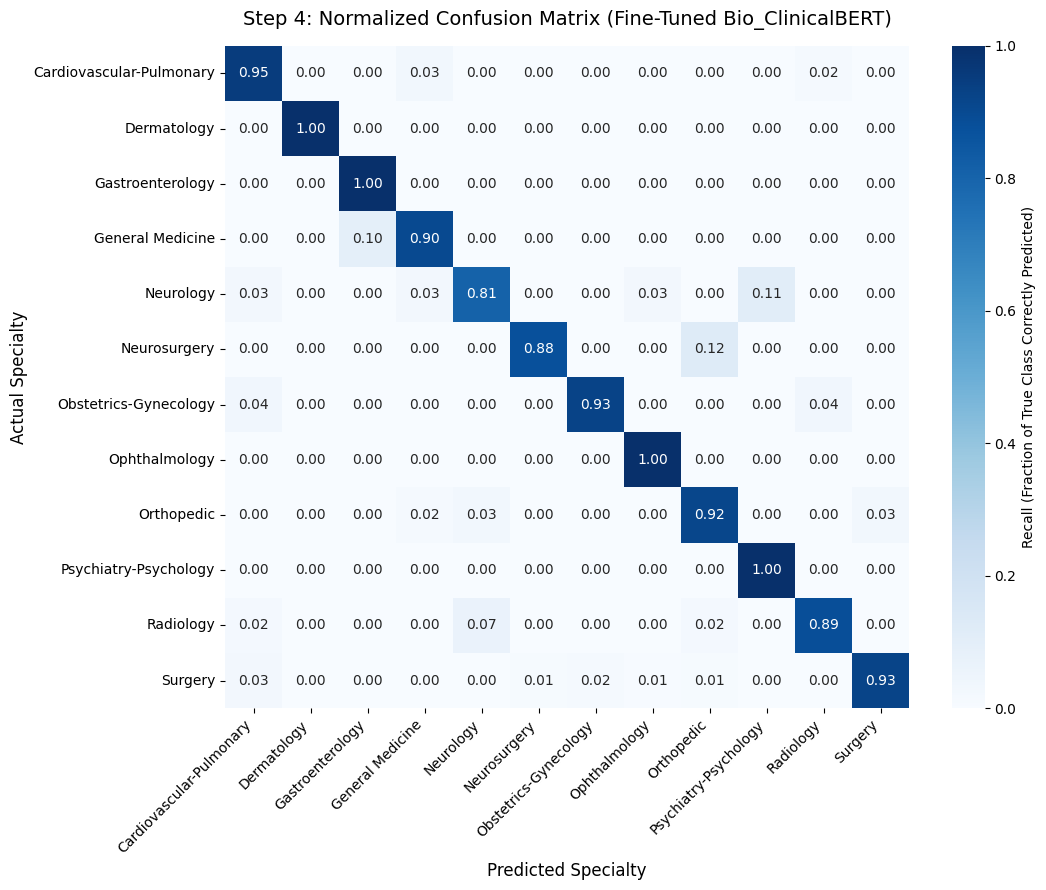

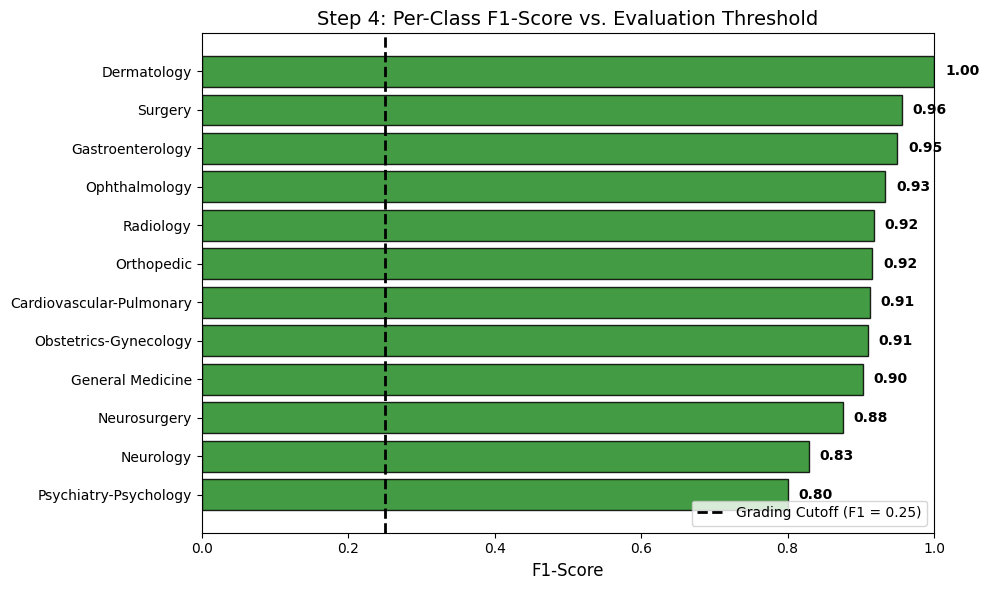

STATISTICAL PERFORMANCE BREAKDOWN BY SPECIALTY


,Specialty,Support (Actual),Correct,Total Predicted,Precision,Recall,F1-Score,Meets Threshold?
1,Dermatology,5,5,5,1.000,1.000,1.000,YES
11,Surgery,175,162,164,0.988,0.926,0.956,YES
2,Gastroenterology,38,38,42,0.905,1.000,0.950,YES
7,Ophthalmology,14,14,16,0.875,1.000,0.933,YES
10,Radiology,44,39,41,0.951,0.886,0.918,YES
8,Orthopedic,59,54,59,0.915,0.915,0.915,YES
0,Cardiovascular-Pulmonary,60,57,65,0.877,0.950,0.912,YES
6,Obstetrics-Gynecology,27,25,28,0.893,0.926,0.909,YES
3,General Medicine,41,37,41,0.902,0.902,0.902,YES
5,Neurosurgery,16,14,16,0.875,0.875,0.875,YES


In [ ]:
labels = sorted(y_val.unique())
acc = accuracy_score(y_val, y_pred)

print("=" * 60)
print(f"STEP 4 (Bio_ClinicalBERT) VALIDATION ACCURACY: {acc * 100:.2f}%")
print("=" * 60)
print("\nClassification Report:")
print(classification_report(y_val, y_pred, digits=3))

# ==============================================================================
# Plot 1: Normalized Confusion Matrix Heatmap
# ==============================================================================
cm_norm = confusion_matrix(y_val, y_pred, labels=labels, normalize='true')

plt.figure(figsize=(11, 9))
sns.heatmap(
    cm_norm, 
    annot=True, 
    fmt='.2f', 
    cmap='Blues', 
    xticklabels=labels, 
    yticklabels=labels,
    cbar_kws={'label': 'Recall (Fraction of True Class Correctly Predicted)'}
)
plt.title('Step 4: Normalized Confusion Matrix (Fine-Tuned Bio_ClinicalBERT)', fontsize=14, pad=15)
plt.xlabel('Predicted Specialty', fontsize=12)
plt.ylabel('Actual Specialty', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ==============================================================================
# Plot 2: Per-Class F1 Score vs. 25% Threshold Bar Chart
# ==============================================================================
report_dict = classification_report(y_val, y_pred, output_dict=True)

f1_data = pd.DataFrame({
    'Specialty': labels,
    'F1_Score': [report_dict[cls]['f1-score'] for cls in labels]
}).sort_values(by='F1_Score', ascending=True)

plt.figure(figsize=(10, 6))
bar_colors = ['crimson' if score < 0.25 else 'forestgreen' for score in f1_data['F1_Score']]
bars = plt.barh(f1_data['Specialty'], f1_data['F1_Score'], color=bar_colors, edgecolor='black', alpha=0.85)

# 0.25 grading cutoff
plt.axvline(x=0.25, color='black', linestyle='--', linewidth=2, label='Grading Cutoff (F1 = 0.25)')
plt.title('Step 4: Per-Class F1-Score vs. Evaluation Threshold', fontsize=14)
plt.xlabel('F1-Score', fontsize=12)
plt.xlim(0, 1.0)

for bar, score in zip(bars, f1_data['F1_Score']):
    plt.text(bar.get_width() + 0.015, bar.get_y() + bar.get_height()/2, f"{score:.2f}", va='center', fontsize=10, fontweight='bold')

plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

# ==============================================================================
# Output Statistics: Per-Class Breakdown Table
# ==============================================================================
cm_raw = confusion_matrix(y_val, y_pred, labels=labels)

stats_summary = []
for i, cls in enumerate(labels):
    actual_count = int(np.sum(cm_raw[i, :]))
    correct_count = int(cm_raw[i, i])
    predicted_count = int(np.sum(cm_raw[:, i]))
    prec = report_dict[cls]['precision']
    rec = report_dict[cls]['recall']
    f1 = report_dict[cls]['f1-score']
    meets_cutoff = "YES" if f1 >= 0.25 else "NO (<0.25)"
    
    stats_summary.append({
        'Specialty': cls,
        'Support (Actual)': actual_count,
        'Correct': correct_count,
        'Total Predicted': predicted_count,
        'Precision': round(prec, 3),
        'Recall': round(rec, 3),
        'F1-Score': round(f1, 3),
        'Meets Threshold?': meets_cutoff
    })

stats_df = pd.DataFrame(stats_summary).sort_values(by='F1-Score', ascending=False)

print("=" * 90)
print("STATISTICAL PERFORMANCE BREAKDOWN BY SPECIALTY")
print("=" * 90)
display(stats_df)

In [ ]:
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader

# 1. Load test_no_labels.csv with header=None
test_df = pd.read_csv(
    'test_no_labels.csv', 
    sep=';', 
    header=None, 
    quotechar='"', 
    on_bad_lines='skip'
)

# Assign standard column names
test_df.columns = ['description', 'sample_name', 'transcription', 'keywords']
print(f"Loaded test set successfully! Total test cases: {len(test_df)}")

# 2. Impute missing values and apply identical clean weighted concatenation
test_df['sample_name'] = test_df['sample_name'].fillna("").astype(str)
test_df['description'] = test_df['description'].fillna("").astype(str)
test_df['keywords'] = test_df['keywords'].fillna("").astype(str)
test_df['transcription'] = test_df['transcription'].fillna("").astype(str)

test_df['clean_weighted_text'] = (
    test_df['sample_name'] + " " + test_df['sample_name'] + " " +
    test_df['description'] + " " +
    test_df['keywords'] + " " + test_df['keywords'] + " " +
    test_df['transcription']
).apply(clean_medical_text)

# 3. Custom Test Dataset with Head+Tail Truncation
class ClinicalTestDataset(Dataset):
    def __init__(self, texts, tokenizer, max_len=512):
        self.texts = list(texts)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        tokens = self.tokenizer.tokenize(text)
        
        # Head + Tail Truncation Strategy (first 256 + last 254 tokens)
        if len(tokens) > (self.max_len - 2):
            tokens = tokens[:256] + tokens[-(self.max_len - 2 - 256):]
            
        token_ids = self.tokenizer.convert_tokens_to_ids(tokens)
        input_ids = [self.tokenizer.cls_token_id] + token_ids + [self.tokenizer.sep_token_id]
        attention_mask = [1] * len(input_ids)

        pad_len = self.max_len - len(input_ids)
        if pad_len > 0:
            input_ids = input_ids + [self.tokenizer.pad_token_id] * pad_len
            attention_mask = attention_mask + [0] * pad_len

        return {
            'input_ids': torch.tensor(input_ids, dtype=torch.long),
            'attention_mask': torch.tensor(attention_mask, dtype=torch.long)
        }

test_dataset = ClinicalTestDataset(test_df['clean_weighted_text'], tokenizer, max_len=512)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

# 4. Predict using the fine-tuned Bio_ClinicalBERT model
print("Generating predictions on test set...")
model_bert.eval()
test_preds = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        
        outputs = model_bert(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1).cpu().numpy()
        test_preds.extend(preds)

# 5. Decode predicted class indices to specialty names
test_pred_labels = le_bert.inverse_transform(test_preds)

# 6. Save directly to results.txt without headers
with open('results.txt', 'w', encoding='utf-8') as f:
    for label in test_pred_labels:
        f.write(f"{label}\n")

print(f"\nSuccessfully generated 'results.txt' with {len(test_pred_labels)} rows!")
print(f"Row count matches test set ({len(test_df)}): {len(test_pred_labels) == len(test_df)}")

# Display predicted distribution summary
print("\nPredicted Class Distribution in Test Set:")
print(pd.Series(test_pred_labels).value_counts())

Loaded test set successfully! Total test cases: 398
Generating predictions on test set...

Successfully generated 'results.txt' with 398 rows!
Row count matches test set (398): True

Predicted Class Distribution in Test Set:
Surgery                     138
Cardiovascular-Pulmonary     46
Radiology                    37
Orthopedic                   36
General Medicine             30
Neurology                    28
Gastroenterology             28
Obstetrics-Gynecology        20
Neurosurgery                 12
Psychiatry-Psychology        11
Ophthalmology                 8
Dermatology                   4
Name: count, dtype: int64
